# What's Driving Negative Duolingo Reviews, and Do Those Complaints Get Better or Worse After App Updates?

*Teenna Pachika and Johanna Garcia · INFO 4360 Course Project · Final Report*

Duolingo is one of the most popular language-learning apps in the world, and most of its Google Play reviews are glowing: 87% give it 4 or 5 stars. But behind those good ratings is a smaller group of unhappy users. In just six weeks this summer, about 4,150 people left a 1- or 2-star review. These users matter because they are the most likely to quit the app, and their reviews are what new users read before they download it.

The problem is that a star rating only tells you that someone is unhappy, not *why*. Duolingo's product team can't read thousands of reviews by hand, so they need a faster way to see what people are complaining about and when it changes. In this report, we find the most common complaints in negative reviews, check whether any of them grew after recent app updates, and turn that into clear recommendations to help the team decide what to fix first.

### How to read this report
Each section builds on the one before it. We start with the data, recap what simple text analysis told us in Phase 2, and then show how we used Claude, an AI model, to label every negative review by complaint type. Finally, we look at how those complaints changed over time and which ones other users agreed with most, and we turn that into recommendations. The code is here so anyone can check our work, but you can follow the story by reading only the text and the charts.

### Contents
1. **The Data:** where the reviews come from and how we cleaned them
2. **What We Learned First:** keywords, sentiment, and topics from Phase 2
3. **Using Claude to Label Complaints:** our prompt, sample outputs, quality checks, and cost
4. **What the Complaints Tell Us:** complaints over time and the ones users agree with most
5. **Key Findings**
6. **What Duolingo Should Do:** recommendations, limitations, and risks
7. **Ethics and Privacy**
8. **AI Usage Log**

In [6]:
# Setting up: libraries, our shared functions, and the data
import sys
sys.path.append("..")

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.preprocessing import load_reviews, get_negative

df = load_reviews()
neg = get_negative(df)

# Showing a chart we already saved in the figures folder (it gets embedded in the HTML export)
def show_figure(name, width=500):
    """Display a saved chart from the figures folder."""
    display(Image(filename=f"../figures/{name}.png", width=width))

print(f"All reviews: {len(df):,} | Negative reviews (1-2 stars): {len(neg):,} ({len(neg) / len(df):.1%})")

All reviews: 50,000 | Negative reviews (1-2 stars): 4,147 (8.3%)


## 1. The Data

We collected our own data. Using a Python package called `google-play-scraper` (see `collect_reviews.ipynb`), we downloaded **50,000 Google Play reviews** of the Duolingo app from US users writing in English. The reviews cover about six weeks, from **July 29 to September 6, 2026** (there is only one review after September 6, so we stop there when we look at trends over time).

Each review has six pieces of information:

| Column | What it means |
|---|---|
| `reviewId` | A unique ID for each review |
| `content` | The text of the review |
| `score` | The star rating, from 1 to 5 |
| `thumbsUpCount` | How many other users marked the review as helpful |
| `reviewCreatedVersion` | The app version the user had when they wrote the review |
| `at` | The date and time the review was posted |

### How we cleaned it
We kept the cleaning simple, because the text was already in good shape (no HTML, links, or empty reviews):
- **Privacy:** we removed usernames and profile pictures before saving the data, so no review can be linked to a person.
- **Dates:** we turned the date column into real dates, so we could group reviews by week.
- **Word count:** we added a column with the number of words in each review.
- **Duplicates:** about 11,800 reviews have the exact same text as another review. When we looked, they were short, positive reviews like "good" or "nice app," not spam, so we kept them. They don't affect the negative reviews we focus on.
- **Missing app versions:** about 4,100 reviews (8%) don't say which app version the user had. Because of this, we use **weeks** as our main way to track changes over time.

The functions we used to load and clean the data are in `src/preprocessing.py`, so every notebook uses the same steps.

In [2]:
# A quick summary of the data
summary = pd.Series({
    "Reviews": len(df),
    "Negative reviews (1-2 stars)": len(neg),
    "1-star reviews": (df["score"] == 1).sum(),
    "2-star reviews": (df["score"] == 2).sum(),
    "Reviews with the same text as another": df.duplicated(subset="content").sum(),
    "Reviews without an app version": df["reviewCreatedVersion"].isna().sum(),
})
summary.to_frame("count")

,count
Reviews,50000
Negative reviews (1-2 stars),4147
1-star reviews,3049
2-star reviews,1098
Reviews with the same text as another,11787
Reviews without an app version,4143


### What the data looks like
Most Duolingo users are happy. Almost three out of four reviews give 5 stars, and only **8.3% (4,147 reviews) give 1 or 2 stars**. Among those negative reviews, 1-star reviews are much more common than 2-star ones (3,049 vs. 1,098): when people are unhappy with the app, they tend to say so strongly.

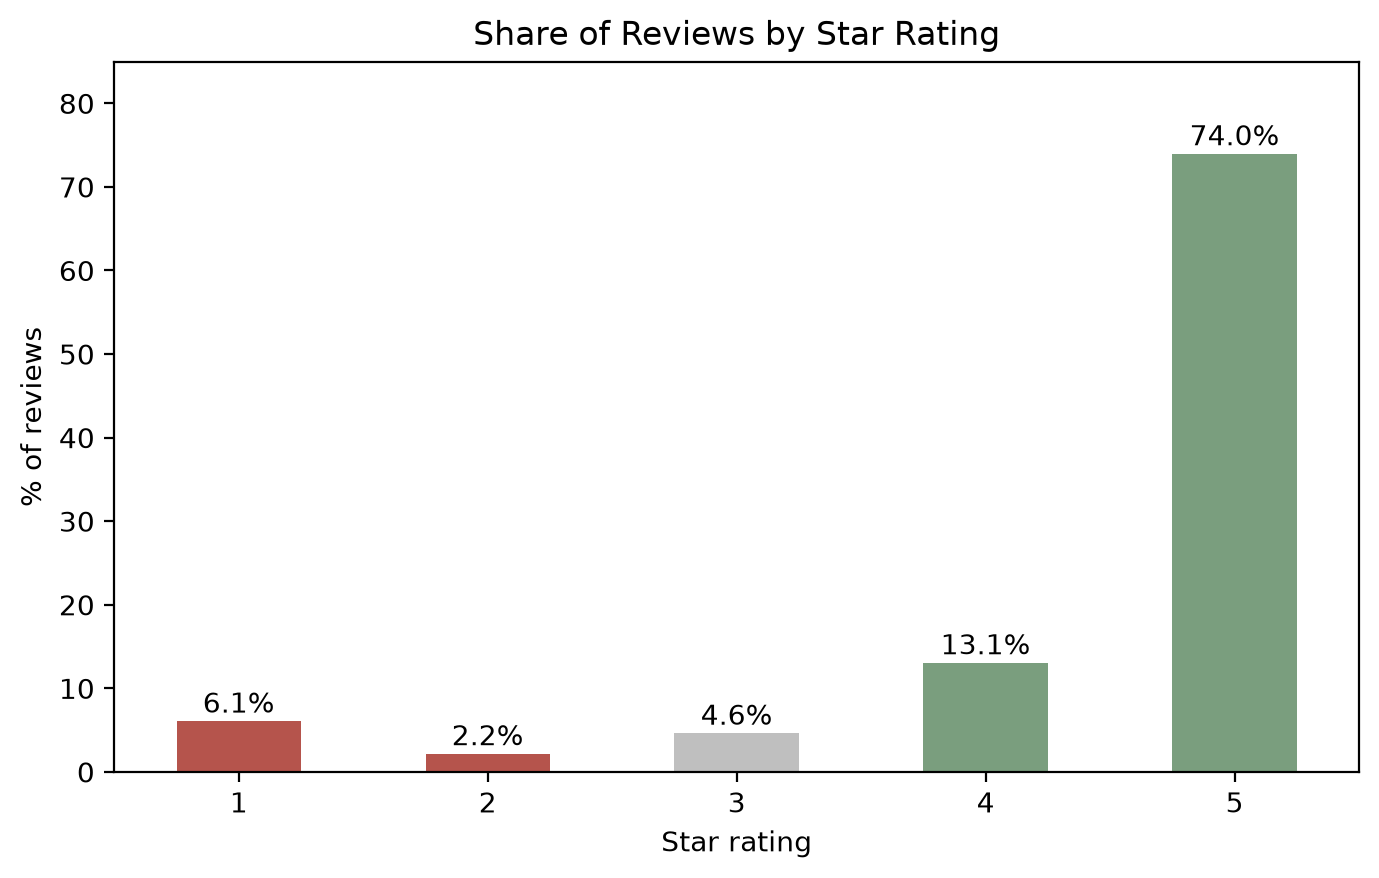

In [7]:
# Showing the star ratings chart
show_figure("01_star_ratings")

Even though unhappy users are a small group, they have a lot more to say. A typical 1- or 2-star review has 17 to 19 words, while a typical 5-star review has only 5, usually something like "great app." This means negative reviews carry most of the detail about what goes wrong.

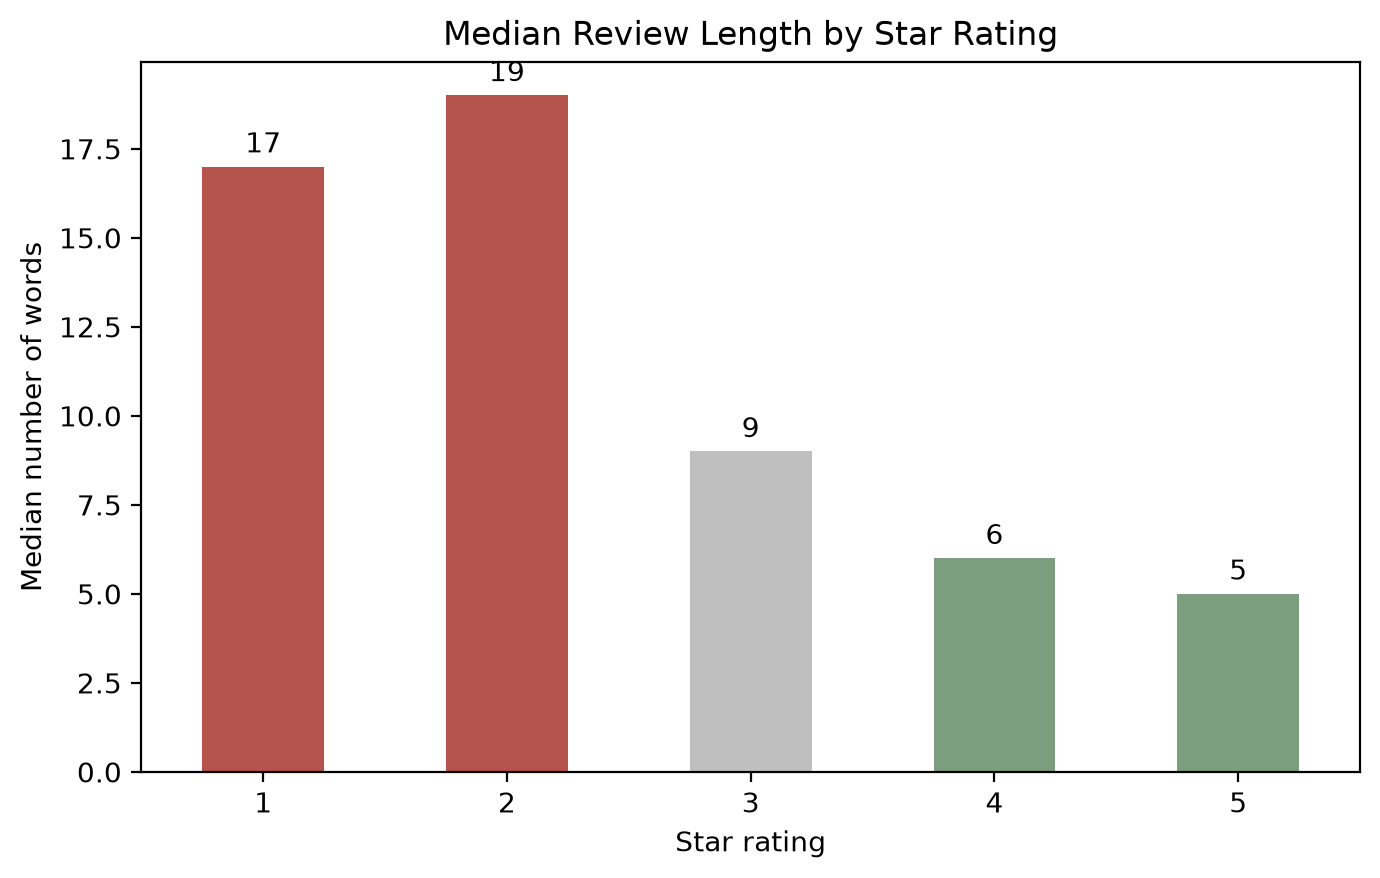

In [8]:
# Showing the length of reviews by star rating chart
show_figure("03_length_by_stars")

The share of negative reviews also changed over time. It stayed around 7.5% for most of August, then jumped to **9.9% in the week ending August 30** and stayed above 9% the week after. Something seems to have made users more unhappy in late August, and finding out what is one of the main goals of this report.

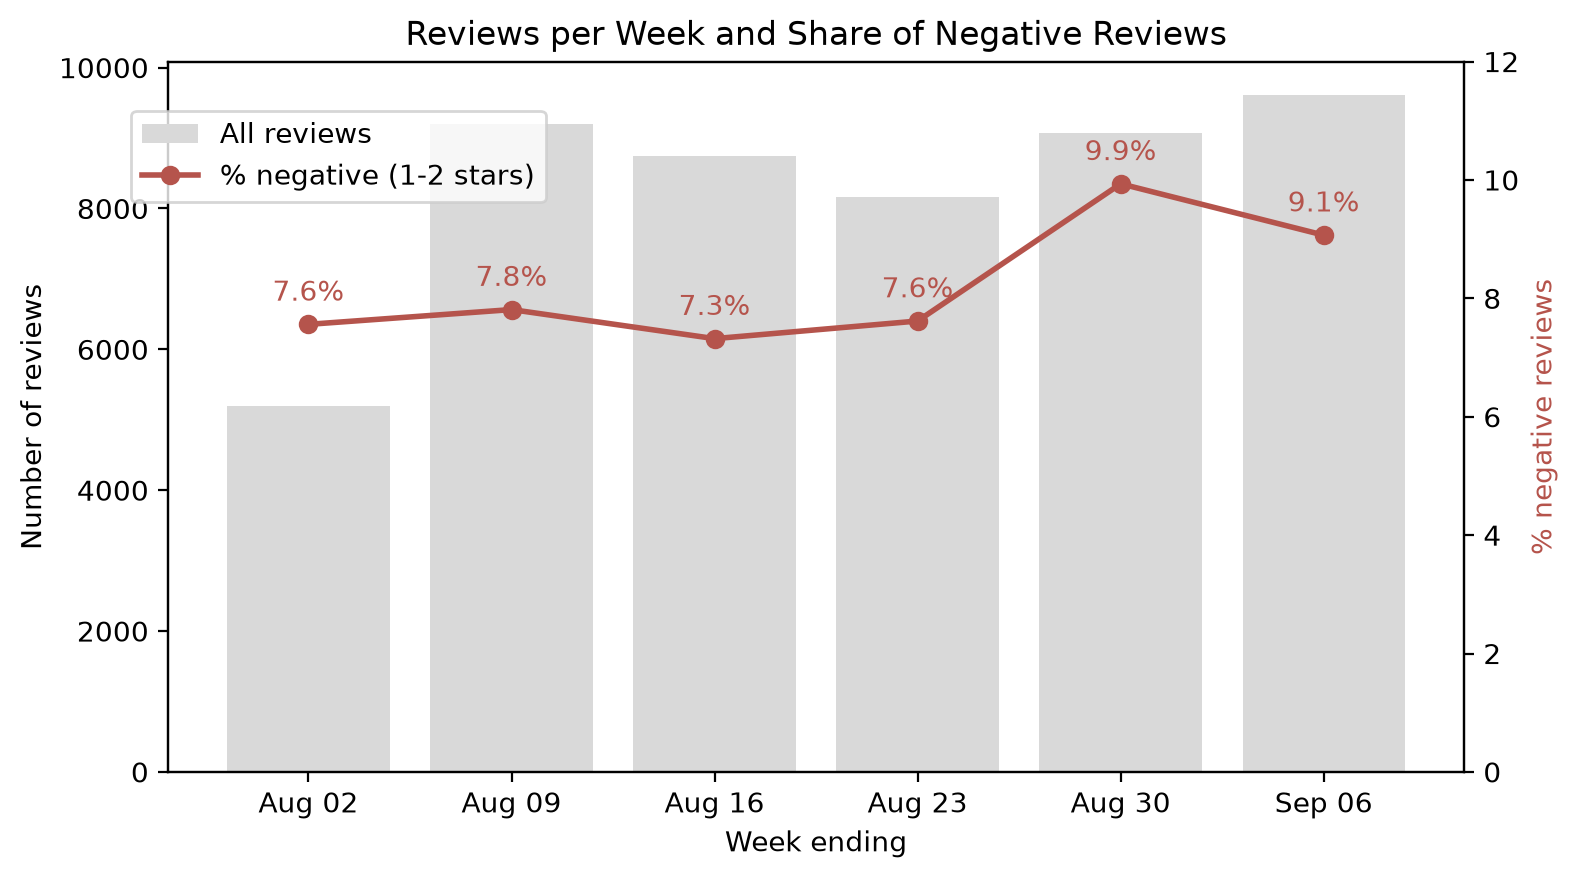

In [9]:
# Showing the reviews over time chart
show_figure("02_reviews_over_time")

**Why we focus on negative reviews:** they are only 8% of all reviews, but they are longer, more detailed, and they rose in late August. For the rest of this report, we look mainly at these **4,147 negative reviews** to understand what users are complaining about.